# Assignment 4 – Numerical greeks (15 points)

**Task.** Two class variables in `Pricer` for the finite difference method (forward, backward, central) and the bump type (absolute, relative), two Enums for the labels,
all combinations for delta and gamma. Compare with the analytic greeks on a set of European options, visualize the numerical error,
compare absolute and relative bumping and suggest optimal bump sizes.

**Code** (this folder starts from the FlatVol lecture: `solution/*.py` + `contract.py`, `enums.py`):
* `enums.py`: `FiniteDifferenceMethod` (`FORWARD`, `BACKWARD`, `CENTRAL`) and `BumpType` (`ABSOLUTE`, `RELATIVE`).
* `pricer.py`: class variables `Pricer.finite_difference_method`, `Pricer.bump_type`, and `Pricer.spot_bump_size`
  (fraction of the spot if relative, currency amount if absolute). `calc_delta` / `calc_gamma` with `GreekMethod.BUMP` evaluate a finite difference stencil
  (`DELTA_STENCILS`, `GAMMA_STENCILS`). The defaults (central, 1% relative) reproduce the lecture's numerical greeks.

**Finite differences** with spot bump $h$ ($h$ itself if absolute, $h = \epsilon S$ if relative):

| | Delta | error | Gamma | error |
| :- | :- | :-: | :- | :-: |
| Forward | $\dfrac{V(S+h) - V(S)}{h}$ | $O(h)$ | $\dfrac{V(S+2h) - 2V(S+h) + V(S)}{h^2}$ | $O(h)$ |
| Backward | $\dfrac{V(S) - V(S-h)}{h}$ | $O(h)$ | $\dfrac{V(S) - 2V(S-h) + V(S-2h)}{h^2}$ | $O(h)$ |
| Central | $\dfrac{V(S+h) - V(S-h)}{2h}$ | $O(h^2)$ | $\dfrac{V(S+h) - 2V(S) + V(S-h)}{h^2}$ | $O(h^2)$ |

The delta formulas and their error orders are those of the finite difference lecture, the central gamma is the formula of the FlatVol lecture.
The one-sided gammas apply the one-sided difference twice (e.g. forward: forward difference of the forward delta), and their $O(h)$ error follows from the same Taylor expansion.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pricer import *

MarketData.initialize()

**Option set.** All four underlyings of the market data, call and put, $K/S_0 \in \{0.8, 0.9, 1, 1.1, 1.2\}$, $T \in \{0.25, 1, 2\}$: 120 options,
priced by `EuropeanAnalyticPricer` with the `FlatVolModel` (the strike-based vol grid makes the numerical delta "sticky strike", so it is comparable with the analytic one).
The error measure is the relative error $|\text{FD} - \text{analytic}| / |\text{analytic}|$.

In [2]:
options = []
for underlying in Stock:
    model = FlatVolModel(underlying)
    for derivative_type in (PutCallFwd.CALL, PutCallFwd.PUT):
        for strike_ratio in (0.8, 0.9, 1.0, 1.1, 1.2):
            for expiry in (0.25, 1.0, 2.0):
                contract = EuropeanContract(underlying, derivative_type, LongShort.LONG, strike_ratio * model.spot, expiry)
                options.append(EuropeanAnalyticPricer(contract, model, Params()))

analytic = {'delta': np.array([p.calc_delta(GreekMethod.ANALYTIC) for p in options]),
            'gamma': np.array([p.calc_gamma(GreekMethod.ANALYTIC) for p in options])}


def numerical_greek(pricer: Pricer, greek: str, method: FiniteDifferenceMethod, bump_type: BumpType, size: float) -> float:
    # instance attributes shadow the class variables, so the settings apply only to this pricer
    pricer.finite_difference_method, pricer.bump_type, pricer.spot_bump_size = method, bump_type, size
    return pricer.calc_delta(GreekMethod.BUMP) if greek == 'delta' else pricer.calc_gamma(GreekMethod.BUMP)


def relative_errors(greek: str, method: FiniteDifferenceMethod, bump_type: BumpType, size: float) -> np.ndarray:
    numeric = np.array([numerical_greek(p, greek, method, bump_type, size) for p in options])
    return np.abs(numeric - analytic[greek]) / np.abs(analytic[greek])

## 1. Numerical error on the option set, lecture default bump (1% relative)

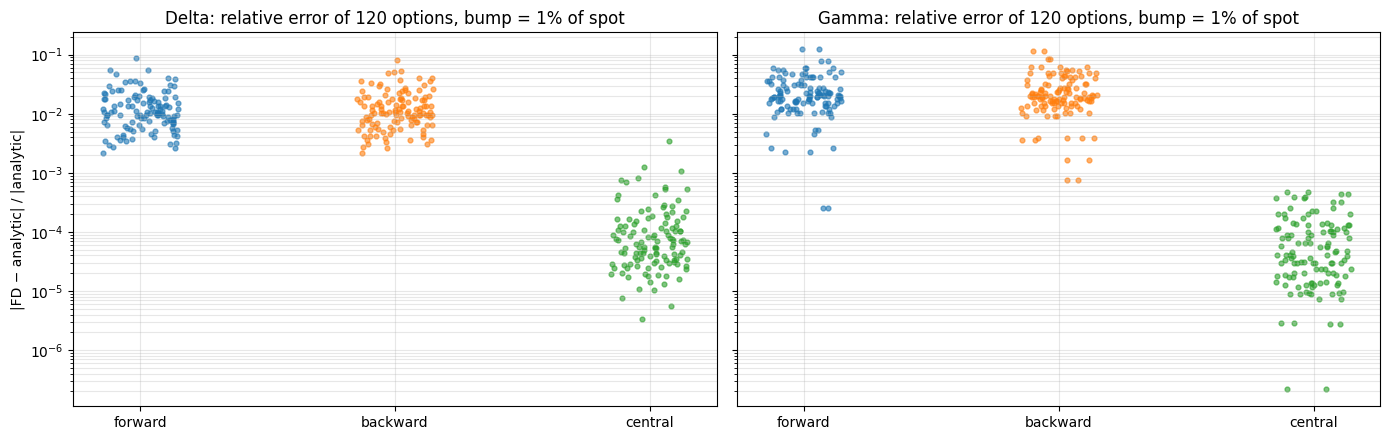

,median,max
delta forward,0.010541,0.088410
delta backward,0.010594,0.081603
delta central,0.000066,0.003404
gamma forward,0.019995,0.122986
gamma backward,0.019626,0.116849
gamma central,0.000041,0.000476


In [3]:
methods = list(FiniteDifferenceMethod)
errors_1pct = {(g, m): relative_errors(g, m, BumpType.RELATIVE, 0.01) for g in ('delta', 'gamma') for m in methods}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
rng = np.random.default_rng(0)
for ax, greek in zip(axes, ('delta', 'gamma')):
    for i, m in enumerate(methods):
        e = errors_1pct[(greek, m)]
        ax.scatter(i + rng.uniform(-0.15, 0.15, len(e)), e, s=12, alpha=0.6)
    ax.set_xticks(range(len(methods)), [m.value.lower() for m in methods])
    ax.set_yscale('log')
    ax.set_title(f'{greek.capitalize()}: relative error of 120 options, bump = 1% of spot')
    ax.grid(alpha=0.3, which='both')
axes[0].set_ylabel('|FD − analytic| / |analytic|')
plt.tight_layout()
plt.show()

pd.DataFrame({f'{g} {m.value.lower()}': [np.median(e), np.max(e)] for (g, m), e in errors_1pct.items()},
             index=['median', 'max']).T

At 1%, as expected from the error orders, the one-sided ($O(h)$) differences are off by up to ~10%, the central ($O(h^2)$) differences are two orders of magnitude better.

## 2. Error as a function of the bump size

Maximum relative error over the 120 options, relative bumps $h/S$ from $10^{-11}$ to $10^{-1}$:

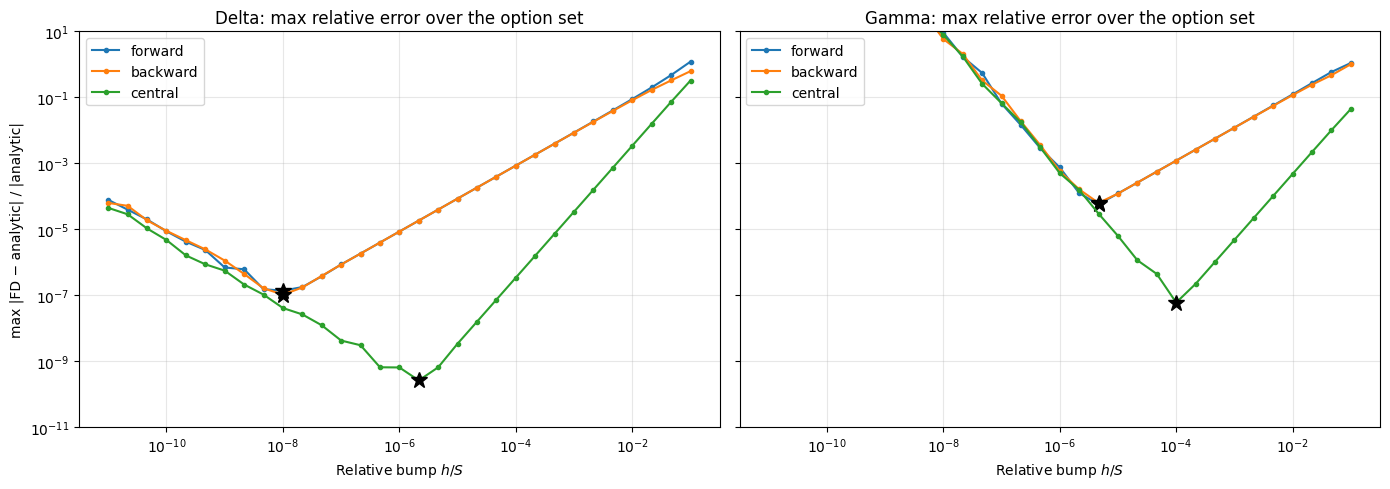

optimal h/S  max rel. error at optimum
greek method                                           
delta forward   1.000000e-08               1.369998e-07
      backward  1.000000e-08               1.036834e-07
      central   2.154435e-06               2.603559e-10
gamma forward   4.641589e-06               5.692368e-05
      backward  4.641589e-06               6.280206e-05
      central   1.000000e-04               5.972740e-08

In [4]:
sizes = np.logspace(-11, -1, 31)
sweep = {(g, m): np.array([relative_errors(g, m, BumpType.RELATIVE, h).max() for h in sizes])
         for g in ('delta', 'gamma') for m in methods}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, greek in zip(axes, ('delta', 'gamma')):
    for m in methods:
        e = sweep[(greek, m)]
        ax.loglog(sizes, e, 'o-', markersize=3, label=m.value.lower())
        ax.plot(sizes[np.argmin(e)], e.min(), 'k*', markersize=12)
    ax.set_title(f'{greek.capitalize()}: max relative error over the option set')
    ax.set_xlabel('Relative bump $h / S$')
    ax.grid(alpha=0.3, which='both')
    ax.legend()
axes[0].set_ylabel('max |FD − analytic| / |analytic|')
axes[0].set_ylim(1e-11, 10)
plt.tight_layout()
plt.show()

optimum = pd.DataFrame([{'greek': g, 'method': m.value.lower(), 'optimal h/S': sizes[np.argmin(e)], 'max rel. error at optimum': e.min()}
                        for (g, m), e in sweep.items()]).set_index(['greek', 'method'])
optimum

Every curve is V-shaped. To the right of the optimum the error of the finite difference formula dominates: slope 1 for the $O(h)$ one-sided, slope 2 for the $O(h^2)$ central differences.
To the left, the prices themselves are only accurate to about 16 digits (floating point), and dividing their tiny difference by $h$ or $h^2$ magnifies this rounding error, so too small bumps are inaccurate too.

## 3. Absolute vs relative bump

Central gamma of the ATM 1-year call of each underlying (spots from 100 to 250), as a function of the absolute bump (left) and of the same bumps expressed relative to the spot (right).

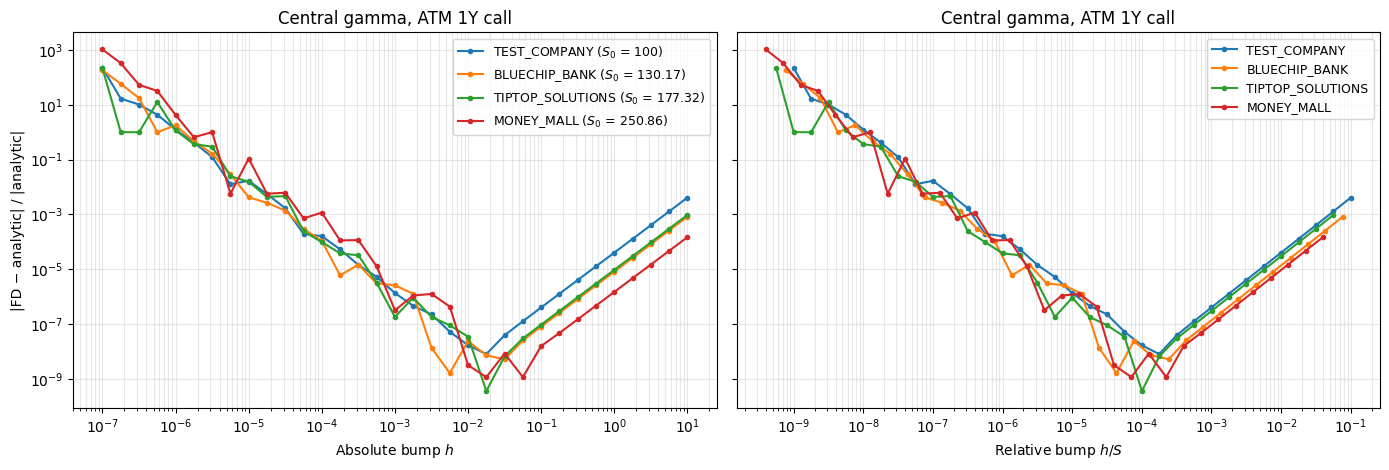

,spot,vol,"rel. error, absolute bump h = 1","rel. error, relative bump h/S = 1%"
underlying,,,,
TEST_COMPANY,100.00,0.30000,0.000040,0.000040
BLUECHIP_BANK,130.17,0.38083,0.000008,0.000014
TIPTOP_SOLUTIONS,177.32,0.32536,0.000009,0.000030
MONEY_MALL,250.86,0.54857,0.000001,0.000009


In [5]:
atm = {}
for underlying in Stock:
    model = FlatVolModel(underlying)
    atm[underlying] = EuropeanAnalyticPricer(
        EuropeanContract(underlying, PutCallFwd.CALL, LongShort.LONG, model.spot, 1.0), model, Params())

absolute_sizes = np.logspace(-7, 1, 33)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
rows = []
for underlying, pricer in atm.items():
    reference = pricer.calc_gamma(GreekMethod.ANALYTIC)
    e = np.array([abs(numerical_greek(pricer, 'gamma', FiniteDifferenceMethod.CENTRAL, BumpType.ABSOLUTE, h) - reference) / reference
                  for h in absolute_sizes])
    spot = pricer.model.spot
    axes[0].loglog(absolute_sizes, e, 'o-', markersize=3, label=f'{underlying.value} ($S_0$ = {spot:g})')
    axes[1].loglog(absolute_sizes / spot, e, 'o-', markersize=3, label=f'{underlying.value}')
    error_at = lambda bump_type, size: abs(numerical_greek(pricer, 'gamma', FiniteDifferenceMethod.CENTRAL, bump_type, size)
                                           - reference) / reference
    rows.append({'underlying': underlying.value, 'spot': spot, 'vol': pricer.model.get_vol(spot, 1.0),
                 'rel. error, absolute bump h = 1': error_at(BumpType.ABSOLUTE, 1.0),
                 'rel. error, relative bump h/S = 1%': error_at(BumpType.RELATIVE, 0.01)})
axes[0].set_xlabel('Absolute bump $h$')
axes[1].set_xlabel('Relative bump $h / S$')
axes[0].set_ylabel('|FD − analytic| / |analytic|')
for ax in axes:
    ax.set_title('Central gamma, ATM 1Y call')
    ax.grid(alpha=0.3, which='both')
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
pd.DataFrame(rows).set_index('underlying')

* With an **absolute** bump the curves are shifted by the spot level: at $h = 1$ the error differs by a factor ~40 between the underlyings.
* With a **relative** bump the curves nearly coincide: at $h/S = 1\%$ the spread is only a factor ~4, the remaining difference coming from the different volatilities.

So the accuracy of a relative bump does not depend on the price level of the underlying. The optimum lies in the flat, noisy bottom of the curves, so it is not a sharp number.

## 4. Recommendation

* **Use relative bumps.** One relative size works for every underlying; an absolute bump that is right for one price level is too small or too large for another.
* **Use central differences.** $O(h^2)$: two orders of magnitude more precise than one-sided differences at the 1% bump, and three orders more precise at their respective optima.
  Central delta and central gamma use the **same three revaluations** $V(S-h), V(S), V(S+h)$, so with one common bump both come at the cost of gamma alone.
* **Bump size: $h/S = 10^{-4}$ for central delta and gamma.** This is the gamma optimum (max relative error $6 \cdot 10^{-8}$ over the option set),
  and delta is still accurate to $3 \cdot 10^{-7}$ there (its own optimum, $h/S \approx 2 \cdot 10^{-6}$, would give $3 \cdot 10^{-10}$, but would need its own pair of revaluations).
  One-sided schemes reach at best $10^{-7}$ (delta, $h/S \approx 10^{-8}$) and $6 \cdot 10^{-5}$ (gamma, $h/S \approx 5 \cdot 10^{-6}$).

In [6]:
recommended = 1e-4
pd.DataFrame({greek: [relative_errors(greek, FiniteDifferenceMethod.CENTRAL, BumpType.RELATIVE, recommended).max()]
              for greek in ('delta', 'gamma')}, index=[f'max rel. error, central, h/S = {recommended:g}'])

,delta,gamma
"max rel. error, central, h/S = 0.0001",3.405677e-07,5.972740e-08
